# Clustering and PCA
Wine Quality dataset (red and white wines)

We look for groups of wines using only the 11 physicochemical variables. Quality and wine type are
not used to build the clusters, only afterwards to see what the clusters mean.

## 0. Libraries and plot style

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colours for the plots
PLUM, PURPLE, LILAC = "#4A1942", "#7D3C98", "#C39BD3"
PINK, ROSE = "#E0719E", "#F5B7C8"
ORANGE, APRICOT = "#E8743B", "#F6A96B"
CREAM, INK = "#FDF1EC", "#3B2A3F"

PALETTE = [PURPLE, PINK, ORANGE, LILAC, APRICOT, PLUM, ROSE]
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_COLORS = {"Low": PURPLE, "Medium": PINK, "High": ORANGE}
TYPE_COLORS = {"red": PLUM, "white": APRICOT}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", ROSE, PINK, PURPLE, PLUM])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [PURPLE, LILAC, "#FFFFFF", APRICOT, ORANGE])

sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBB8CF", "axes.labelcolor": INK, "axes.titlecolor": PLUM,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": "#F1E4EC", "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "text.color": INK,
})

FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Figure saved ->", FIG_DIR / name)

In [2]:
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol"]

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette

RES_DIR = Path("../results")
RES_DIR.mkdir(exist_ok=True)

SEED = 42
wine = pd.read_csv("../data/wine_clean.csv")
wine["quality_class"] = pd.Categorical(wine["quality_class"], categories=CLASS_ORDER, ordered=True)
X_std = StandardScaler().fit_transform(wine[FEATURES])   # K-Means and PCA need standardised data
print(X_std.shape)

(5320, 11)


## 1. Number of clusters (elbow and silhouette)

k with the highest silhouette: 2


Figure saved -> ../results/figures/clu_kmeans_selection.png


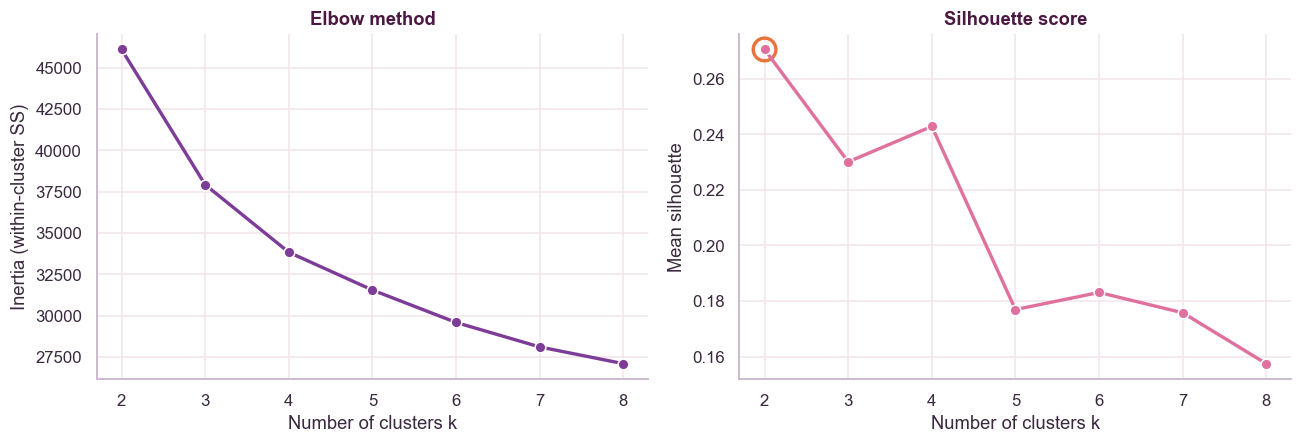

In [3]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_std)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_std, km.labels_))
best_k = list(ks)[int(np.argmax(silhouette))]
print("k with the highest silhouette:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(ks, inertia, "o-", color=PURPLE, lw=2.2, ms=7, markeredgecolor="white")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (within-cluster SS)")
axes[1].plot(ks, silhouette, "o-", color=PINK, lw=2.2, ms=7, markeredgecolor="white")
axes[1].scatter(best_k, max(silhouette), s=220, facecolor="none", edgecolor=ORANGE, lw=2.2)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Mean silhouette")
fig.tight_layout()
save(fig, "clu_kmeans_selection.png")
plt.show()

## 2. PCA explained variance

Figure saved -> ../results/figures/clu_pca_variance.png


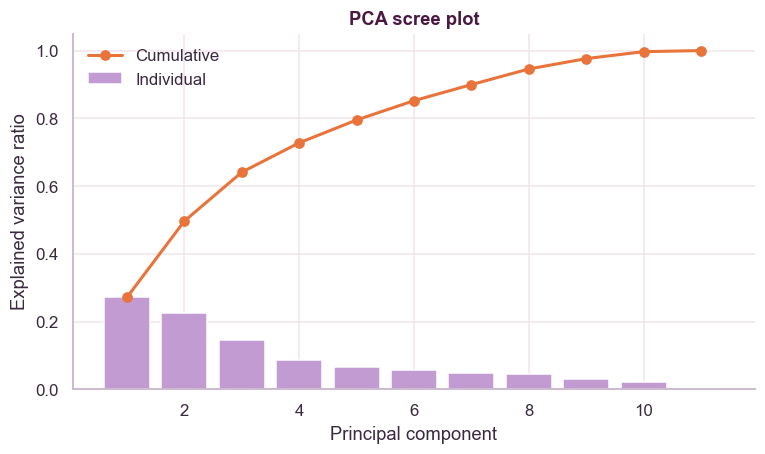

Variance explained by PC1 + PC2: 0.497


In [4]:
pca = PCA().fit(X_std)
ev = pca.explained_variance_ratio_
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(range(1, len(ev) + 1), ev, color=LILAC, edgecolor="white", label="Individual")
ax.plot(range(1, len(ev) + 1), np.cumsum(ev), "o-", color=ORANGE, lw=2, label="Cumulative")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA scree plot")
ax.legend()
save(fig, "clu_pca_variance.png")
plt.show()
print("Variance explained by PC1 + PC2:", round(ev[:2].sum(), 3))

## 3. Clusters on the first two principal components

Figure saved -> ../results/figures/clu_pca_projection.png


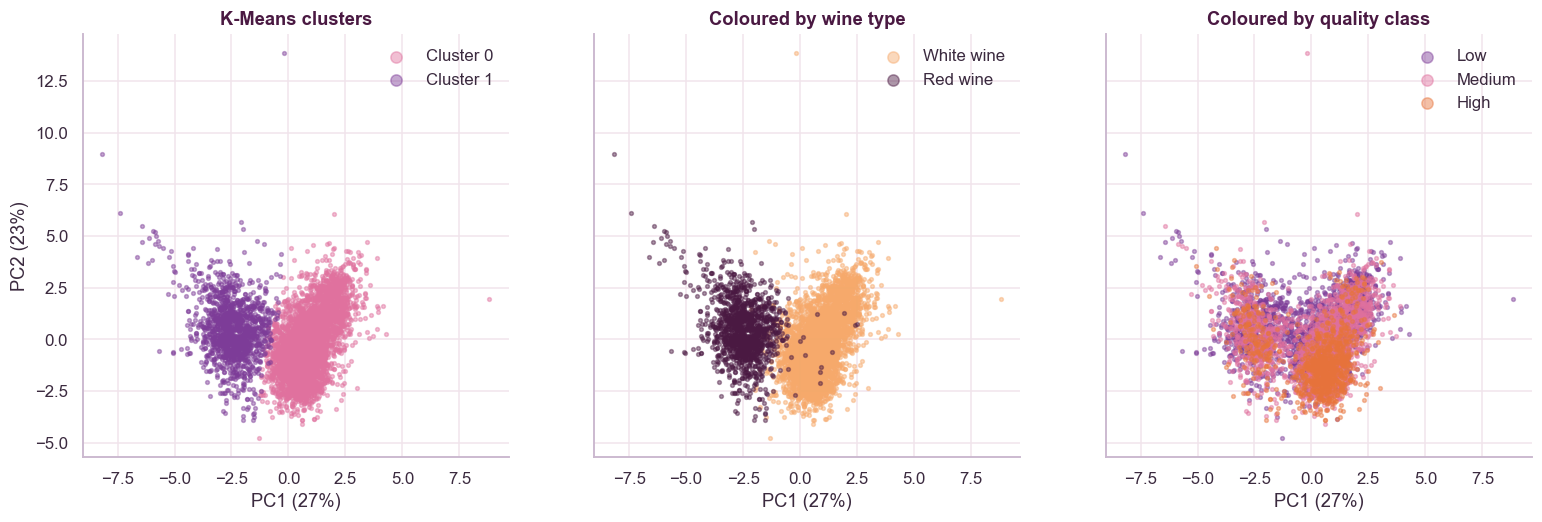

In [5]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(X_std)
wine["cluster"] = km.labels_
Z = pca.transform(X_std)[:, :2]

cluster_colors = [PINK, PURPLE, ORANGE, LILAC, APRICOT, PLUM, ROSE, "#9C5B8E"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for c in range(best_k):
    m = wine.cluster == c
    axes[0].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.45, color=cluster_colors[c], label=f"Cluster {c}")
for t in ["white", "red"]:
    m = wine.wine_type == t
    axes[1].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.45, color=TYPE_COLORS[t], label=f"{t.capitalize()} wine")
for c in CLASS_ORDER:
    m = wine.quality_class == c
    axes[2].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.45, color=CLASS_COLORS[c], label=c)
for ax, title in zip(axes, ["K-Means clusters", "Coloured by wine type", "Coloured by quality class"]):
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({ev[0]:.0%})")
    ax.legend(markerscale=3, loc="upper right")
axes[0].set_ylabel(f"PC2 ({ev[1]:.0%})")
save(fig, "clu_pca_projection.png")
plt.show()

## 4. What do the clusters represent?

In [6]:
display(pd.crosstab(wine.cluster, wine.wine_type, margins=True))
display(pd.crosstab(wine.cluster, wine.quality_class, normalize="index").round(2))
print("ARI clusters vs wine type    :", round(adjusted_rand_score(wine.wine_type, wine.cluster), 3))
print("ARI clusters vs quality class:", round(adjusted_rand_score(wine.quality_class, wine.cluster), 3))

wine_type,red,white,All
cluster,,,
0,22,3896,3918
1,1337,65,1402
All,1359,3961,5320


quality_class,Low,Medium,High
cluster,,,
0,0.33,0.46,0.21
1,0.49,0.38,0.13


ARI clusters vs wine type    : 0.932
ARI clusters vs quality class: 0.003


## 5. What do the principal components mean?

The loadings are the weights of each original (standardised) variable in a component. The
biplot draws them as arrows on top of the projected wines.

,PC1,PC2
volatile acidity,-0.39,0.07
chlorides,-0.32,0.27
sulphates,-0.32,0.16
fixed acidity,-0.27,0.31
pH,-0.19,-0.19
density,-0.14,0.57
alcohol,-0.03,-0.47
citric acid,0.13,0.22
residual sugar,0.30,0.37
free sulfur dioxide,0.43,0.14


Figure saved -> ../results/figures/clu_pca_biplot.png


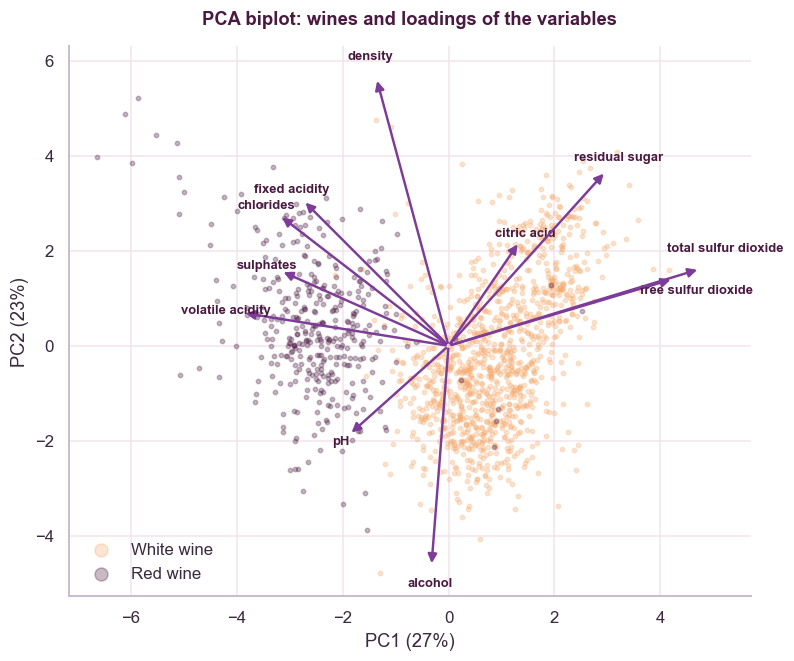

In [7]:
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
loadings.round(3).to_csv(RES_DIR / "pca_loadings.csv")
display(loadings.sort_values("PC1").round(2))

rng = np.random.default_rng(0)
idx = rng.choice(len(Z), 1500, replace=False)
fig, ax = plt.subplots(figsize=(8, 6.5))
for t in ["white", "red"]:
    m = idx[wine.wine_type.values[idx] == t]
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.3, color=TYPE_COLORS[t], label=f"{t.capitalize()} wine")
scale = 0.85 * np.abs(Z[idx]).max() / np.abs(loadings.values).max()
nudge = {"free sulfur dioxide": (0.1, -0.35), "total sulfur dioxide": (0.1, 0.3)}
for name, (l1, l2) in loadings.iterrows():
    ax.annotate("", xy=(l1 * scale, l2 * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=PURPLE, lw=1.6))
    dx, dy = nudge.get(name, (0, 0))
    ax.text(l1 * scale * 1.08 + dx, l2 * scale * 1.08 + dy, name, fontsize=8.5, color=PLUM,
            ha="center", va="center", weight="semibold")
ax.set_xlabel(f"PC1 ({ev[0]:.0%})")
ax.set_ylabel(f"PC2 ({ev[1]:.0%})")
ax.set_title("PCA biplot: wines and loadings of the variables", pad=14)
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.6)
lo, hi = ax.get_xlim()
ax.set_xlim(lo, hi + 1.0)
ax.legend(markerscale=3, loc="lower left")
save(fig, "clu_pca_biplot.png")
plt.show()

## 6. Other clustering methods: Ward and Gaussian mixtures

K-Means looks for compact spherical groups. We compare it with two methods that make different
assumptions: agglomerative clustering with Ward linkage (hierarchical, no need to fix k in
advance) and a Gaussian mixture model (soft assignments, elliptical clusters, k chosen with BIC).

k with the lowest BIC: 10
Figure saved -> ../results/figures/clu_ward_gmm.png


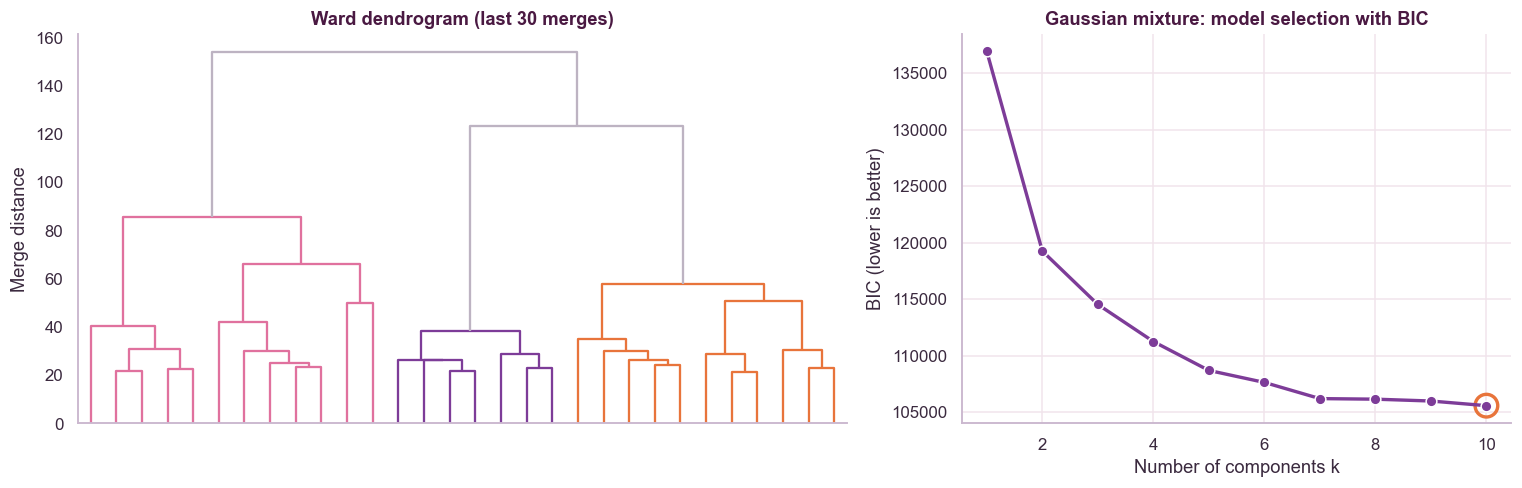

In [8]:
Zw = linkage(X_std, method="ward")

ks_gmm = range(1, 11)
bic = [GaussianMixture(k, covariance_type="full", n_init=3, random_state=SEED).fit(X_std).bic(X_std)
       for k in ks_gmm]
k_bic = list(ks_gmm)[int(np.argmin(bic))]
print("k with the lowest BIC:", k_bic)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
set_link_color_palette([PINK, PURPLE, ORANGE, LILAC])
dendrogram(Zw, truncate_mode="lastp", p=30, ax=axes[0], color_threshold=Zw[-2, 2] * 0.999,
           above_threshold_color="#BDB3C2", no_labels=True)
axes[0].set_title("Ward dendrogram (last 30 merges)")
axes[0].set_ylabel("Merge distance")
axes[0].grid(False)
axes[1].plot(ks_gmm, bic, "o-", color=PURPLE, lw=2.2, ms=7, markeredgecolor="white")
axes[1].scatter(k_bic, min(bic), s=220, facecolor="none", edgecolor=ORANGE, lw=2.2)
axes[1].set_xlabel("Number of components k")
axes[1].set_ylabel("BIC (lower is better)")
axes[1].set_title("Gaussian mixture: model selection with BIC")
fig.tight_layout()
save(fig, "clu_ward_gmm.png")
plt.show()

In [9]:
def describe(labels, name):
    return {"method": name, "k": len(np.unique(labels)),
            "silhouette": silhouette_score(X_std, labels),
            "ARI type": adjusted_rand_score(wine.wine_type, labels),
            "NMI type": normalized_mutual_info_score(wine.wine_type, labels),
            "ARI quality": adjusted_rand_score(wine.quality_class, labels),
            "NMI quality": normalized_mutual_info_score(wine.quality_class, labels)}

labels = {
    "K-Means (k=2)": KMeans(2, n_init=10, random_state=SEED).fit_predict(X_std),
    "Ward (k=2)": fcluster(Zw, 2, criterion="maxclust"),
    "GMM (k=2)": GaussianMixture(2, covariance_type="full", n_init=3, random_state=SEED).fit(X_std).predict(X_std),
    "K-Means (k=4)": KMeans(4, n_init=10, random_state=SEED).fit_predict(X_std),
    "Ward (k=4)": fcluster(Zw, 4, criterion="maxclust"),
    f"GMM (k={k_bic}, BIC)": GaussianMixture(k_bic, covariance_type="full", n_init=3,
                                            random_state=SEED).fit(X_std).predict(X_std),
}
comparison = pd.DataFrame([describe(l, n) for n, l in labels.items()]).set_index("method")
comparison.round(3).to_csv(RES_DIR / "clustering_comparison.csv")
display(comparison.round(3))

wine["kmeans4"] = labels["K-Means (k=4)"]
display(pd.crosstab(wine.kmeans4, wine.wine_type))
display(pd.crosstab(wine.kmeans4, wine.quality_class, normalize="index").round(2))

,k,silhouette,ARI type,NMI type,ARI quality,NMI quality
method,,,,,,
K-Means (k=2),2,0.270,0.932,0.862,0.003,0.013
Ward (k=2),2,0.261,0.875,0.786,0.004,0.014
GMM (k=2),2,0.242,0.771,0.685,0.009,0.021
K-Means (k=4),4,0.243,0.406,0.493,0.026,0.051
Ward (k=4),4,0.223,0.440,0.509,0.014,0.043
"GMM (k=10, BIC)",10,0.050,0.159,0.368,0.034,0.070


wine_type,red,white
kmeans4,,
0,774,80
1,38,2435
2,4,1402
3,543,44


quality_class,Low,Medium,High
kmeans4,,,
0,0.59,0.35,0.06
1,0.24,0.47,0.29
2,0.48,0.45,0.08
3,0.38,0.41,0.21


## 7. Clustering inside each wine type

With all the wines together the main structure is the colour of the wine, which is not very
interesting. Here we standardise and cluster red and white wines separately and check if the
groups found inside one type are related to quality.

Figure saved -> ../results/figures/clu_within_type.png


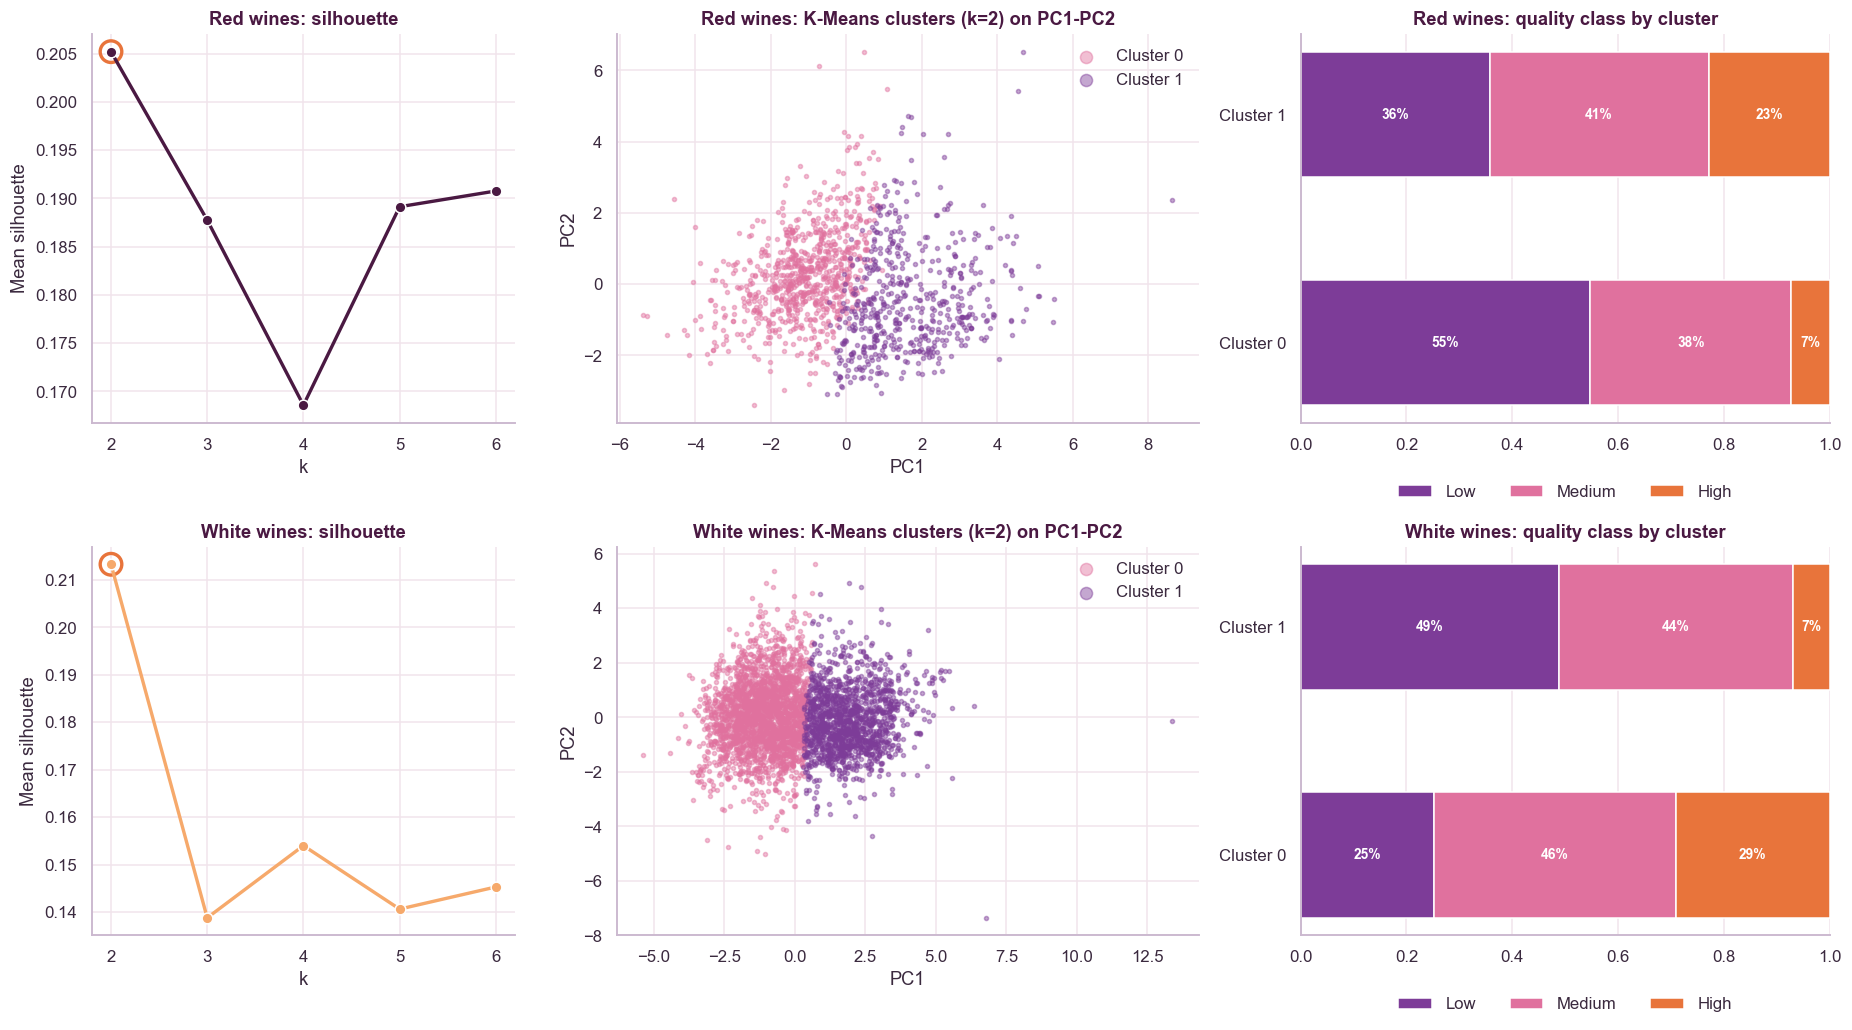

,wine type,method,k,silhouette,ARI quality,NMI quality
0,red,K-Means,2,0.205,0.048,0.037
1,red,Ward,2,0.206,0.039,0.018
2,white,K-Means,2,0.213,0.032,0.060
3,white,Ward,2,0.182,0.020,0.049


red


,n wines,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,% High,% Low
cluster,,,,,,,,,,,,,,,
0,813,7.32,0.61,0.15,2.39,0.08,16.62,49.00,1.0,3.38,0.60,10.32,5.46,7.26,54.74
1,546,9.79,0.42,0.46,2.72,0.10,14.81,43.59,1.0,3.21,0.75,10.59,5.86,22.89,35.71


white


,n wines,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,% High,% Low
cluster,,,,,,,,,,,,,,,
0,2484,6.75,0.28,0.32,3.42,0.04,28.30,116.08,0.99,3.21,0.49,11.17,6.04,29.11,25.24
1,1477,6.99,0.29,0.37,10.11,0.06,45.98,172.70,1.00,3.17,0.50,9.61,5.54,6.91,48.82


In [10]:
within_rows, profiles, sil_curves = [], {}, {}
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), gridspec_kw={"width_ratios": [0.8, 1.1, 1]})
for r, t in enumerate(["red", "white"]):
    sub = wine[wine.wine_type == t].reset_index(drop=True)
    Xt = StandardScaler().fit_transform(sub[FEATURES])
    sil_curves[t] = {k: silhouette_score(Xt, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xt))
                     for k in range(2, 7)}
    k_t = max(sil_curves[t], key=sil_curves[t].get)
    km_t = KMeans(k_t, n_init=10, random_state=SEED).fit(Xt)
    sub["cluster"] = km_t.labels_
    ward_t = fcluster(linkage(Xt, method="ward"), k_t, criterion="maxclust")
    for method, lab in [("K-Means", sub["cluster"]), ("Ward", ward_t)]:
        within_rows.append({"wine type": t, "method": method, "k": k_t,
                            "silhouette": silhouette_score(Xt, lab),
                            "ARI quality": adjusted_rand_score(sub.quality_class, lab),
                            "NMI quality": normalized_mutual_info_score(sub.quality_class, lab)})
    prof = sub.groupby("cluster")[FEATURES + ["quality"]].mean()
    prof.insert(0, "n wines", sub.groupby("cluster").size())
    prof["% High"] = 100 * sub.groupby("cluster")["quality_class"].apply(lambda s: (s == "High").mean())
    prof["% Low"] = 100 * sub.groupby("cluster")["quality_class"].apply(lambda s: (s == "Low").mean())
    profiles[t] = prof
    prof.round(3).to_csv(RES_DIR / f"cluster_profiles_{t}.csv")

    ax = axes[r, 0]
    ax.plot(list(sil_curves[t]), list(sil_curves[t].values()), "o-", color=TYPE_COLORS[t], lw=2.2, ms=7,
            markeredgecolor="white")
    ax.scatter(k_t, sil_curves[t][k_t], s=200, facecolor="none", edgecolor=ORANGE, lw=2.2)
    ax.set_title(f"{t.capitalize()} wines: silhouette")
    ax.set_xlabel("k")
    ax.set_ylabel("Mean silhouette")

    Zt = PCA(2).fit_transform(Xt)
    ax = axes[r, 1]
    for c in range(k_t):
        m = sub.cluster == c
        ax.scatter(Zt[m, 0], Zt[m, 1], s=7, alpha=0.45, color=cluster_colors[c], label=f"Cluster {c}")
    ax.set_title(f"{t.capitalize()} wines: K-Means clusters (k={k_t}) on PC1-PC2")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(markerscale=3, loc="upper right")

    ax = axes[r, 2]
    share = pd.crosstab(sub.cluster, sub.quality_class, normalize="index")[CLASS_ORDER]
    left = np.zeros(len(share))
    for c in CLASS_ORDER:
        ax.barh([f"Cluster {i}" for i in share.index], share[c], left=left, color=CLASS_COLORS[c],
                label=c, height=0.55)
        for i, v in enumerate(share[c]):
            if v > 0.06:
                ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white",
                        fontsize=9, weight="bold")
        left += share[c].values
    ax.set_xlim(0, 1)
    ax.set_title(f"{t.capitalize()} wines: quality class by cluster")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
save(fig, "clu_within_type.png")
plt.show()

within = pd.DataFrame(within_rows)
within.round(3).to_csv(RES_DIR / "clustering_within_type.csv", index=False)
display(within.round(3))
for t in profiles:
    print(t)
    display(profiles[t].round(2))

## Summary

* With all the wines together, every method finds the same thing: the two clusters are the two
  wine types, and they have nothing to do with quality (ARI close to 0).
* The silhouette prefers k=2 because the red/white split is by far the largest gap in the data.
  Larger k and other methods (Ward, GMM) split the white wines further, but still not by quality.
* Inside each wine type the clusters are only weakly related to quality: some groups have more
  High wines than others (mostly the ones with more alcohol), but the overlap is large.